<a id="decision-trees-classifying-outflow-intensity-and-net-migration-direction"></a>

# Decision trees: classifying outflow intensity and net migration direction

This notebook completes question 9 with two separate targets and combines their results with the inflow Naive Bayes analysis.

**Question 9, outflows and net direction:** How accurately can characteristics classify these outcomes? **Input:** the validated analysis dataset. **Cohort:** the shared 2023 county split, with balanced counties excluded from binary net classification. **Purpose:** evaluate tree rules against target-specific baselines.


<a id="overview"></a>

## Overview

A decision tree divides the characteristic space through a sequence of binary rules. Internal nodes compare one characteristic with a threshold; a leaf predicts the most common training class among its counties. Trees capture nonlinear thresholds and interactions and support inspection of individual decision paths. Deep trees can isolate small groups and overfit, so depth and minimum leaf size constrain complexity.

Impurity measures how well a split in a tree divides observations by class. A tree chooses splits that reduce impurity. Here are some common measure of impurity:
- Gini impurity is 1 − Σ pₖ². It reaches zero in a pure node and increases as classes mix.
- Entropy is −Σ pₖ log₂(pₖ), with zero-probability terms treated as zero.
- Information gain is parent entropy minus the sample-weighted entropy of the children.

The Gini criterion uses Gini reduction, while the entropy criterion uses information gain.

For a worked example, start with ten counties: six net-inflow and four net-outflow. Split into a left child with four inflow and zero outflow, and a right child with two inflow and four outflow. Parent entropy is about 0.971 bits, child-weighted entropy about 0.551 bits, and information gain about 0.420 bits. The code below verifies these values.

Allowing arbitrary depth and arbitrary thresholds creates an unbounded theoretical space of tree structures. For a fixed finite dataset, only finitely many distinct threshold-induced partitions exist; specified features and stopping rules constrain the fitted trees further.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.dummy import DummyClassifier
from us_migration.supervised import (FEATURES, LABELS, SEED, RATE_CLASSES, NET_CLASSES,
    prepare_classification, task_rows, export_context, sample, evaluate, figure,
    comparison_plot, tree_structure, records, write_json, configure_plots)
configure_plots()
SOURCE = ROOT / 'data/processed/analysis_county_year.parquet'
counties, X, thresholds = prepare_classification(pd.read_parquet(SOURCE))
from us_migration.exports import begin_analysis, finish_analysis
BUNDLE = begin_analysis(ROOT, 'classification/decision-trees')
context = export_context(BUNDLE, SOURCE, counties, thresholds)
OUT = BUNDLE/'data'
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
display(pd.DataFrame(thresholds, index=['Low/medium boundary', 'Medium/high boundary']))
display(counties.groupby(['classification_split', 'net_class']).size().unstack(fill_value=0))
assert len(counties) == 3050 and X.shape == (3050, 13)
assert counties.classification_split.value_counts().to_dict() == {'train': 2440, 'test': 610}

,inflow,outflow
Low/medium boundary,39.008023,38.995502
Medium/high boundary,50.447417,47.030690


net_class,Balanced,Net inflow,Net outflow
classification_split,,,
test,0,352,258
train,8,1466,966


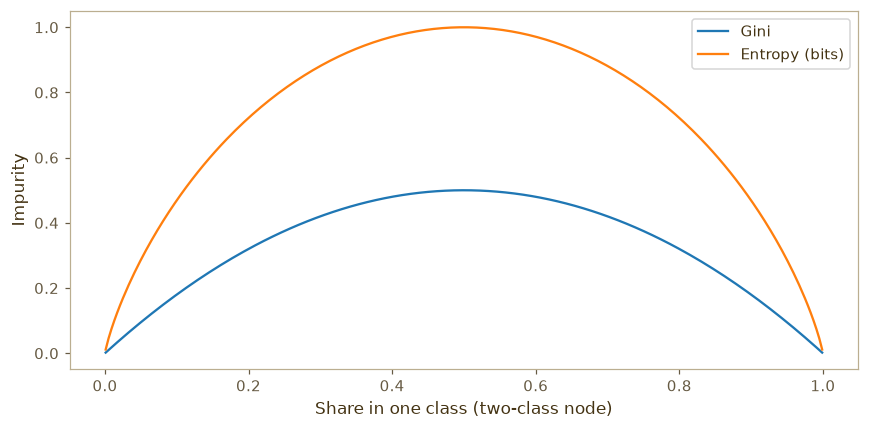

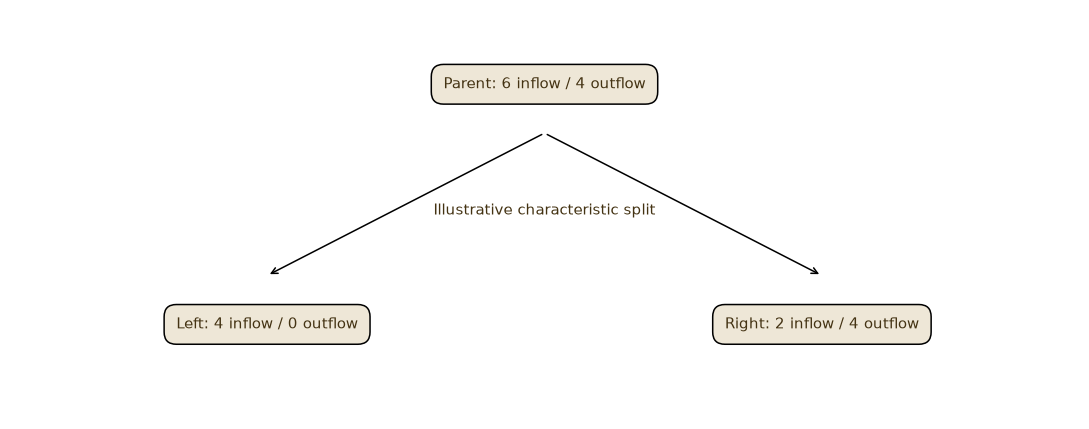

parent_entropy            0.970951
weighted_child_entropy    0.550978
information_gain          0.419973
dtype: float64

In [2]:
# Two overview illustrations, separate from fitted result trees.
p = np.linspace(.001, .999, 250)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(p, 1-p*p-(1-p)**2, label='Gini')
ax.plot(p, -p*np.log2(p)-(1-p)*np.log2(1-p), label='Entropy (bits)')
ax.set(xlabel='Share in one class (two-class node)', ylabel='Impurity')
ax.legend()
figure(fig, BUNDLE, 'tree-overview-impurity', svg=True)
fig, ax = plt.subplots(figsize=(10, 4))
ax.axis('off')
for xy, text in [((.5,.82),'Parent: 6 inflow / 4 outflow'),((.24,.23),'Left: 4 inflow / 0 outflow'),((.76,.23),'Right: 2 inflow / 4 outflow')]:
    ax.text(*xy, text, ha='center', va='center', bbox=dict(boxstyle='round,pad=.8', fc='#eee7d7'))
for end in [(.24,.35),(.76,.35)]:
    ax.annotate('', xy=end, xytext=(.5,.7), arrowprops={'arrowstyle':'->'})
ax.text(.5,.5,'Illustrative characteristic split',ha='center')
figure(fig, BUNDLE, 'tree-overview-split', svg=True)
def entropy(counts):
    p = np.array(counts, dtype=float)/sum(counts)
    p = p[p>0]
    return float(-(p*np.log2(p)).sum())
parent = entropy([6,4])
children = .4*entropy([4,0]) + .6*entropy([2,4])
gain = parent - children
assert np.isclose(gain, .4199730940219749)
worked_example = {'parent_entropy':parent, 'weighted_child_entropy':children, 'information_gain':gain}
display(pd.Series(worked_example))

<a id="data-prep"></a>

## Data Prep

One observation represents one eligible county in 2023. We start with the post-cleaning `analysis_county_year.parquet` and retain the same 3,050 counties used in PCA and clustering. Alaska and Connecticut state substitutes stay outside this county cross-section. Each county receives equal weight. Six counties inherit socioeconomic predictor imputation fitted on 2009–2018 observations; existing outlier flags are retained.

The 13 predictors cover population, age, income, home value, rent, poverty, unemployment, vacancy, homeownership, education, FEMA incidents, precipitation and temperature. Population and monetary values use log10; incidents use log1p. These deterministic transformations precede splitting. Identifiers, migration counts/rates, migration-derived clusters and audit flags are kept outside the feature matrix. Learned transformations are fitted separately within training folds.

A supervised classifier needs labeled examples: a predictor row X and an observed target y. FIPS-sorted counties receive a seeded 80/20 split. Training has 2,440 counties and testing has 610. Their FIPS sets are disjoint, so a county used to fit the classifier cannot also supply its final test score.

Binning migration variables into low/medium/high inflow and outflow each use the training distribution's 1/3 and 2/3 quantiles (linear interpolation). Low includes the first boundary; medium includes the second; high exceeds it. The thresholds define the classification task and remain fixed through cross-validation and test labeling. Net outflow is negative and net inflow positive; the eight exactly balanced counties are reported separately and excluded only from the binary task.

Five shuffled stratified training folds (seed 42) select hyperparameters by mean macro-F1, which weights classes equally. Test results are inspected only after selection.

[Shared profiles and split membership](../website/data/supervised/county-profiles.csv) · [Cohort provenance](../website/data/supervised/context.json)

Outflow samples: [labeled source](../website/data/supervised/outflow-labeled-source.csv),
[training inputs](../website/data/supervised/outflow-characteristics-train.csv),
[test inputs](../website/data/supervised/outflow-characteristics-test.csv).
Net samples: [labeled source](../website/data/supervised/net-labeled-source.csv),
[training inputs](../website/data/supervised/net-characteristics-train.csv),
[test inputs](../website/data/supervised/net-characteristics-test.csv).
Training/test sample row keys are exported separately for each target.


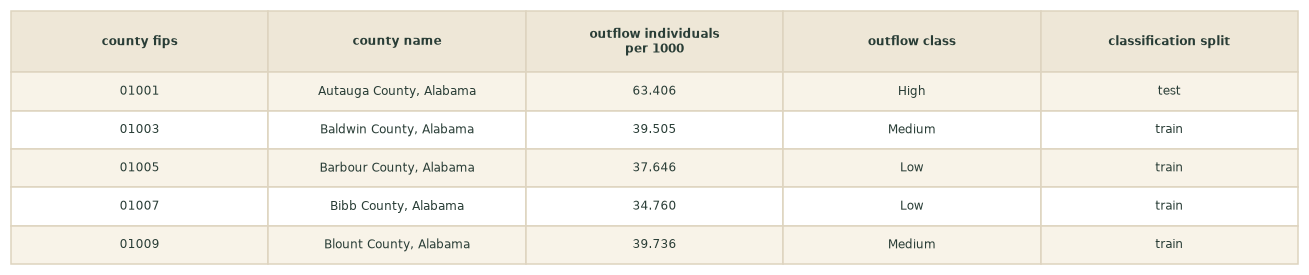

,log10_population,median_age,log10_income,log10_home_value,log10_rent,poverty_pct,unemployment_pct,vacancy_pct,homeownership_pct,bachelors_plus_pct,log1p_incidents,precipitation_inches,temperature_f,target
1,5.380112,43.7,4.875171,5.457882,3.083144,10.514699,3.194281,26.358954,77.535344,32.797637,0.000000,49.37,69.883333,Medium
2,4.393698,40.7,4.646306,5.040998,2.808886,21.921478,5.708618,22.406426,67.488987,11.464715,0.693147,49.11,66.691667,Low
3,4.345413,41.3,4.709397,5.122544,2.904174,20.511585,9.984000,16.710671,77.176067,11.468207,0.000000,46.88,64.666667,Low
4,4.772996,40.9,4.786013,5.229682,2.870989,14.095287,5.835173,11.358045,79.505847,15.579030,0.000000,53.83,63.208333,Medium
5,4.006765,40.4,4.564938,4.899821,2.802774,25.651127,5.873181,24.176548,63.509991,8.999729,0.000000,52.96,66.025000,Low


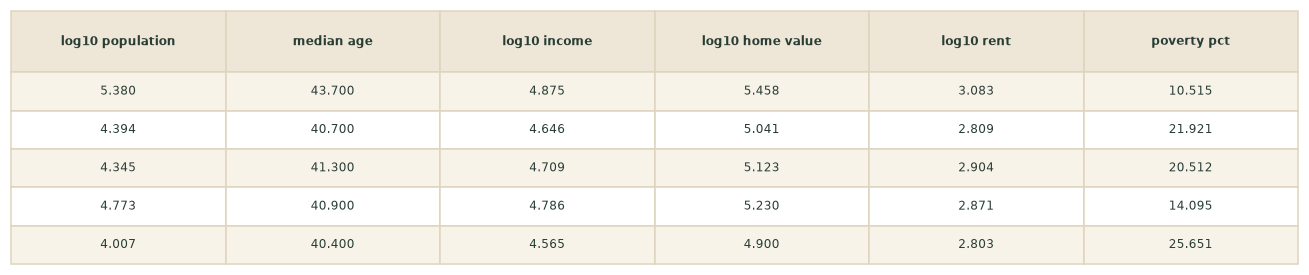

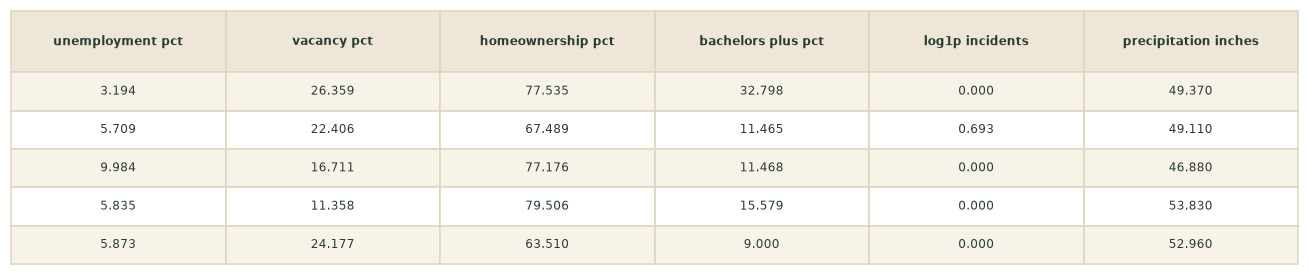

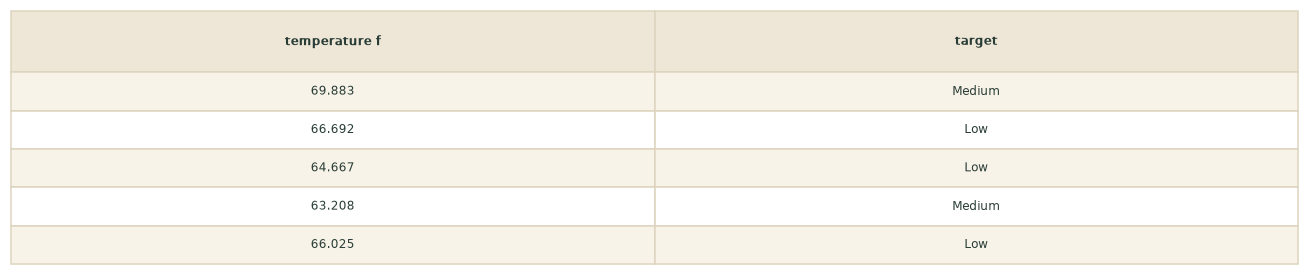

,log10_population,median_age,log10_income,log10_home_value,log10_rent,poverty_pct,unemployment_pct,vacancy_pct,homeownership_pct,bachelors_plus_pct,log1p_incidents,precipitation_inches,temperature_f,target
0,4.772945,39.2,4.844110,5.296446,3.079181,10.684306,2.541559,8.928066,74.910092,28.282680,0.693147,49.81,66.291667,High
14,4.183384,42.3,4.726882,5.158965,2.898725,13.154754,1.545364,14.650518,80.047871,18.211951,0.000000,49.96,62.708333,Medium
22,4.694746,38.0,4.732032,5.110926,2.936011,18.710967,6.797488,13.710170,61.343518,19.327855,0.000000,49.77,67.616667,High
29,4.504851,38.6,4.711748,5.107210,2.824126,17.374750,3.597329,16.985320,71.758820,14.889393,0.000000,49.72,62.550000,Low
30,4.426934,44.0,4.707153,5.079904,2.879096,19.053205,4.915210,15.969733,78.274882,13.316464,0.000000,46.40,68.016667,Medium


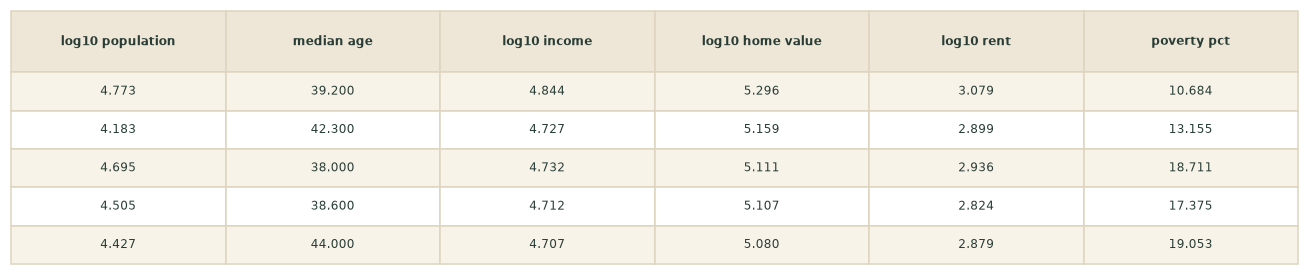

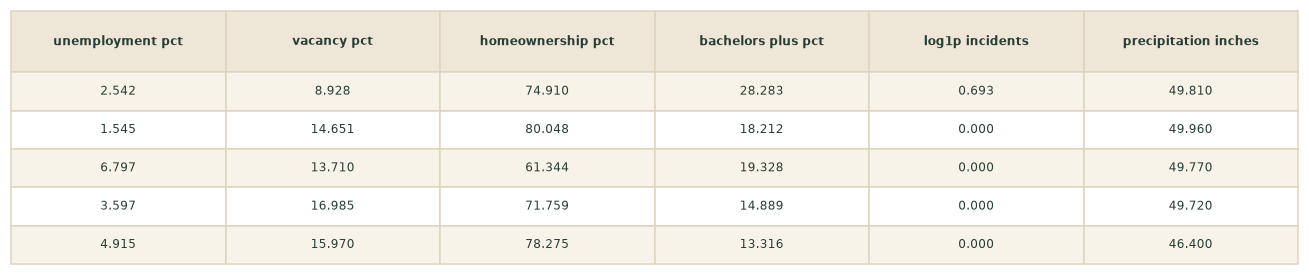

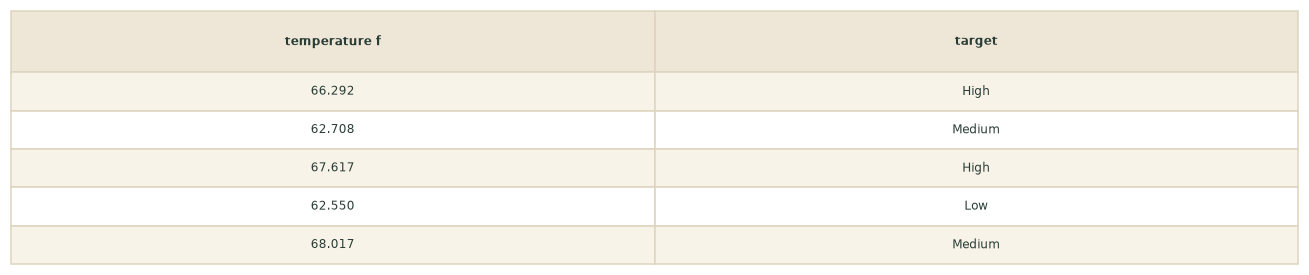

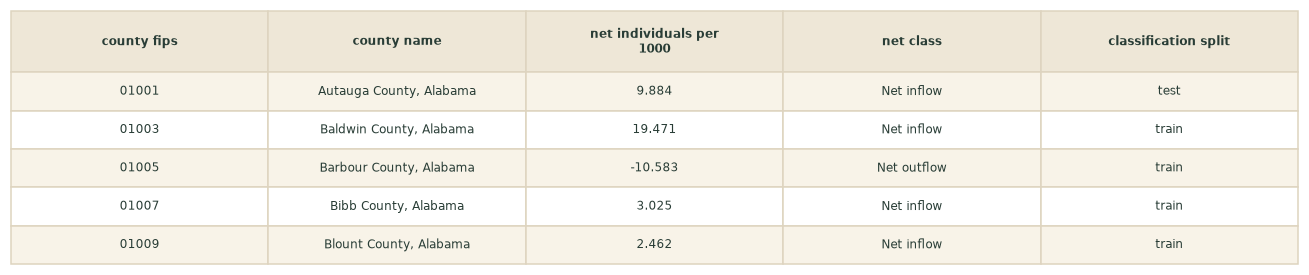

,log10_population,median_age,log10_income,log10_home_value,log10_rent,poverty_pct,unemployment_pct,vacancy_pct,homeownership_pct,bachelors_plus_pct,log1p_incidents,precipitation_inches,temperature_f,target
1,5.380112,43.7,4.875171,5.457882,3.083144,10.514699,3.194281,26.358954,77.535344,32.797637,0.000000,49.37,69.883333,Net inflow
2,4.393698,40.7,4.646306,5.040998,2.808886,21.921478,5.708618,22.406426,67.488987,11.464715,0.693147,49.11,66.691667,Net outflow
3,4.345413,41.3,4.709397,5.122544,2.904174,20.511585,9.984000,16.710671,77.176067,11.468207,0.000000,46.88,64.666667,Net inflow
4,4.772996,40.9,4.786013,5.229682,2.870989,14.095287,5.835173,11.358045,79.505847,15.579030,0.000000,53.83,63.208333,Net inflow
5,4.006765,40.4,4.564938,4.899821,2.802774,25.651127,5.873181,24.176548,63.509991,8.999729,0.000000,52.96,66.025000,Net outflow


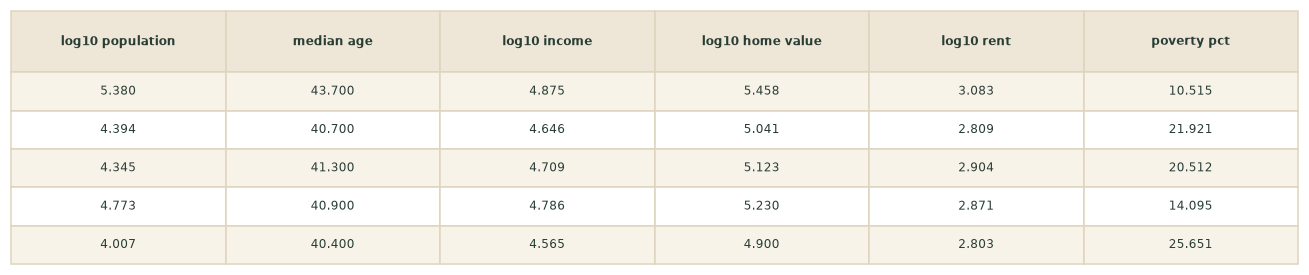

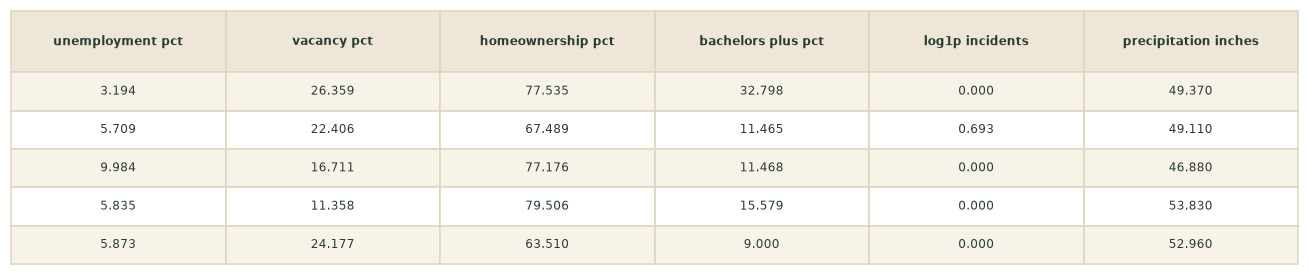

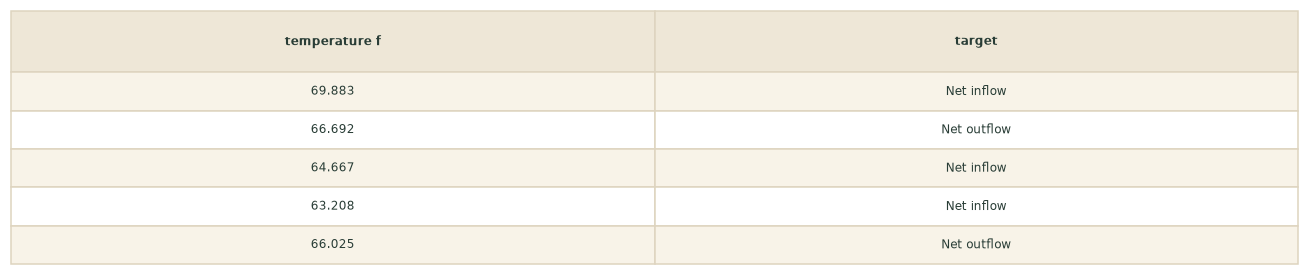

,log10_population,median_age,log10_income,log10_home_value,log10_rent,poverty_pct,unemployment_pct,vacancy_pct,homeownership_pct,bachelors_plus_pct,log1p_incidents,precipitation_inches,temperature_f,target
0,4.772945,39.2,4.844110,5.296446,3.079181,10.684306,2.541559,8.928066,74.910092,28.282680,0.693147,49.81,66.291667,Net inflow
14,4.183384,42.3,4.726882,5.158965,2.898725,13.154754,1.545364,14.650518,80.047871,18.211951,0.000000,49.96,62.708333,Net inflow
22,4.694746,38.0,4.732032,5.110926,2.936011,18.710967,6.797488,13.710170,61.343518,19.327855,0.000000,49.77,67.616667,Net outflow
29,4.504851,38.6,4.711748,5.107210,2.824126,17.374750,3.597329,16.985320,71.758820,14.889393,0.000000,49.72,62.550000,Net outflow
30,4.426934,44.0,4.707153,5.079904,2.879096,19.053205,4.915210,15.969733,78.274882,13.316464,0.000000,46.40,68.016667,Net inflow


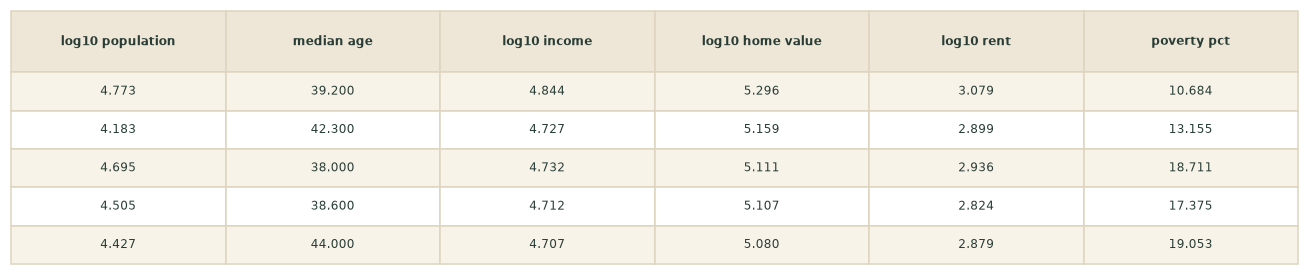

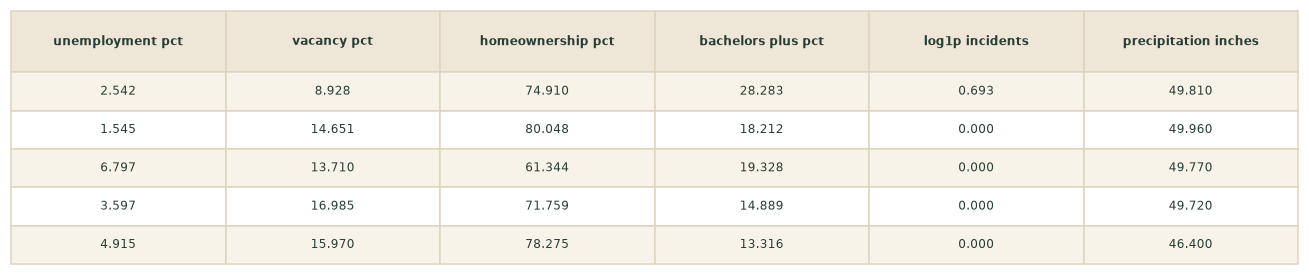

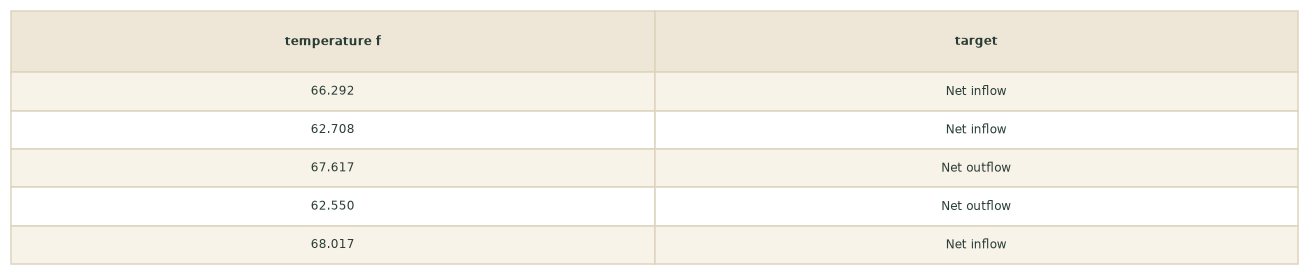

In [3]:
samples_by_task = {}
for outcome in ['outflow', 'net']:
    x_train, x_test, y_train, y_test = task_rows(counties, X, outcome)
    source_columns = ['county_fips','county_name',outcome+'_individuals_per_1000',outcome+'_class','classification_split']
    eligible = counties.loc[x_train.index.union(x_test.index)]
    samples_by_task[outcome] = [sample(eligible[source_columns], BUNDLE, outcome+'-labeled-source')]
    for split, x, y in [('train',x_train,y_train),('test',x_test,y_test)]:
        display(x.assign(target=y).sort_index().head())
        samples_by_task[outcome].append(sample(x.assign(target=y), BUNDLE, outcome+'-characteristics-'+split))
        counties.loc[x.sort_index().head(20).index, ['county_fips','county_name','classification_split']].to_csv(OUT/f'{outcome}-{split}-sample-keys.csv',index=False)
    assert set(counties.loc[x_train.index,'county_fips']).isdisjoint(counties.loc[x_test.index,'county_fips'])

<a id="code"></a>

## Code

For each target, compare 18 configurations: depths 2/4/6 × minimum leaf sizes 10/25/50 × Gini/entropy. All counties have equal weight. Five-fold macro-F1 selects a model for each of the two classification tasks: Classifying migration outflow intensity and net migration direction. Exact ties are resolved by shallower depth, larger leaves, then Gini. Trees use feature thresholds without standardization, so predictors remain continuous after their existing log transformations.

For interpretation, also retain the best validation configuration at each of the three requested depths. These six fitted training trees illustrate increasing complexity. Only each classification task's selected model receives a final test evaluation. Cross-validation comparisons include training scores and validation fold standard deviations to show fit and variability.

### Outflow candidate comparison

,max_depth,min_samples_leaf,criterion,mean_train_score,mean_test_score,std_test_score
0,6,10,entropy,0.608724,0.517194,0.022304
1,4,10,entropy,0.557182,0.516354,0.016764
2,6,50,entropy,0.571186,0.511032,0.008304
3,4,25,entropy,0.555249,0.510897,0.014897
4,4,50,entropy,0.548900,0.510782,0.013860
5,4,25,gini,0.565661,0.508000,0.013801
6,4,10,gini,0.570142,0.506851,0.012850
7,4,50,gini,0.560882,0.505362,0.013097
8,6,25,entropy,0.595611,0.502842,0.008108
9,6,50,gini,0.580906,0.501062,0.011401


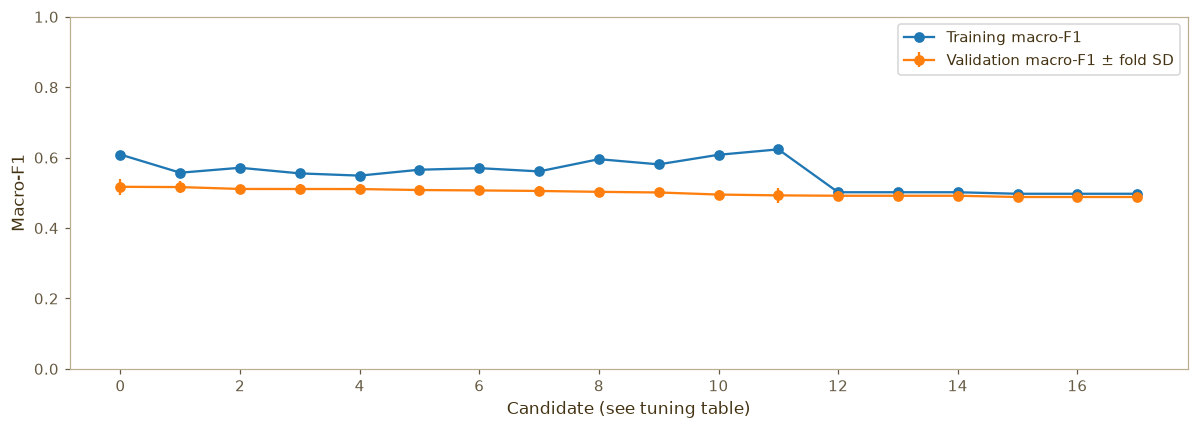

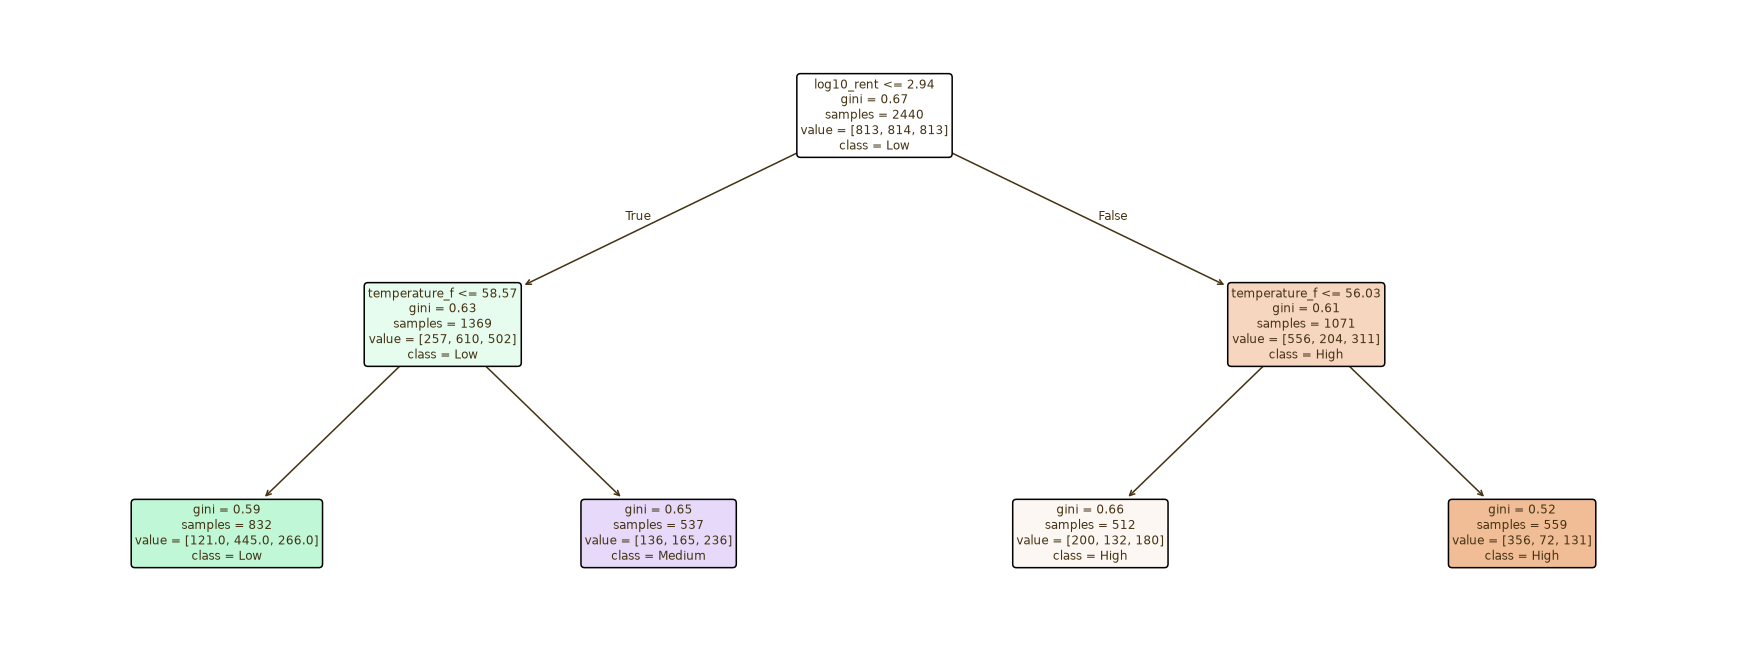

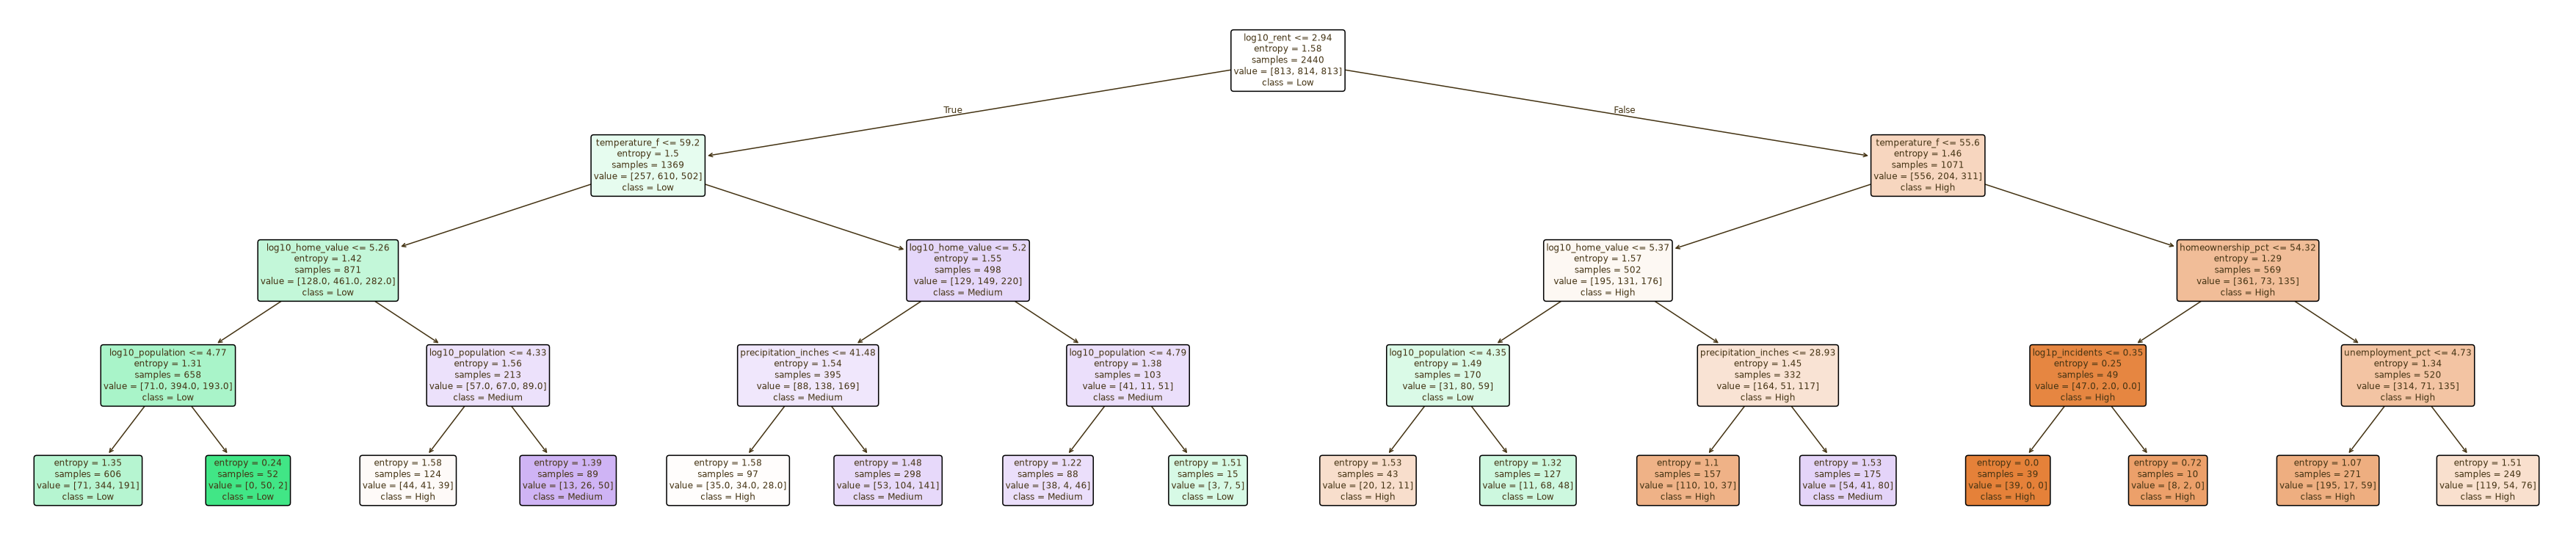



### Net candidate comparison

,max_depth,min_samples_leaf,criterion,mean_train_score,mean_test_score,std_test_score
0,4,50,entropy,0.691129,0.672405,0.013166
1,6,25,entropy,0.736356,0.671514,0.022229
2,6,10,gini,0.756786,0.671393,0.018449
3,6,50,entropy,0.719550,0.671381,0.016093
4,6,50,gini,0.719447,0.671189,0.017219
5,6,10,entropy,0.744268,0.670775,0.015465
6,6,25,gini,0.740393,0.667238,0.015763
7,4,50,gini,0.695728,0.666013,0.014496
8,4,10,gini,0.698852,0.665658,0.020442
9,4,25,entropy,0.689826,0.665527,0.010939


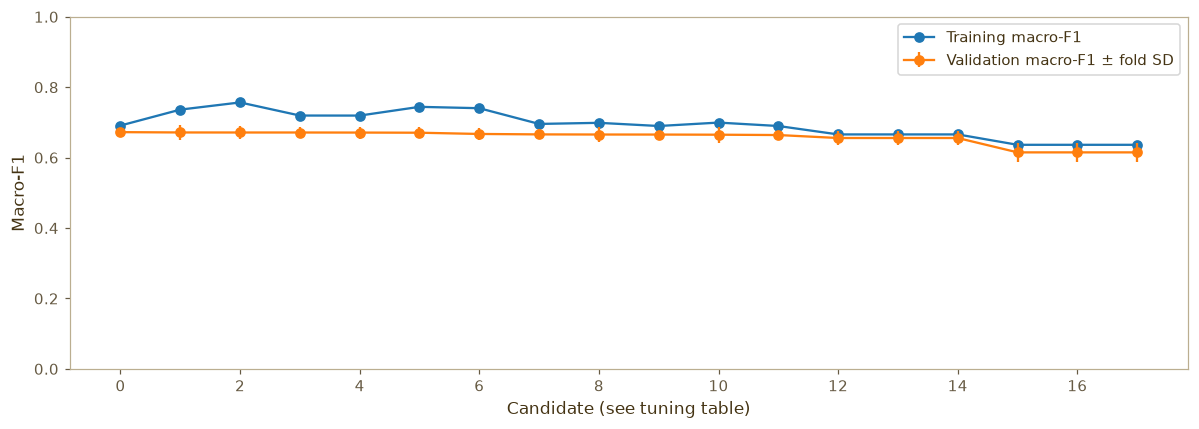

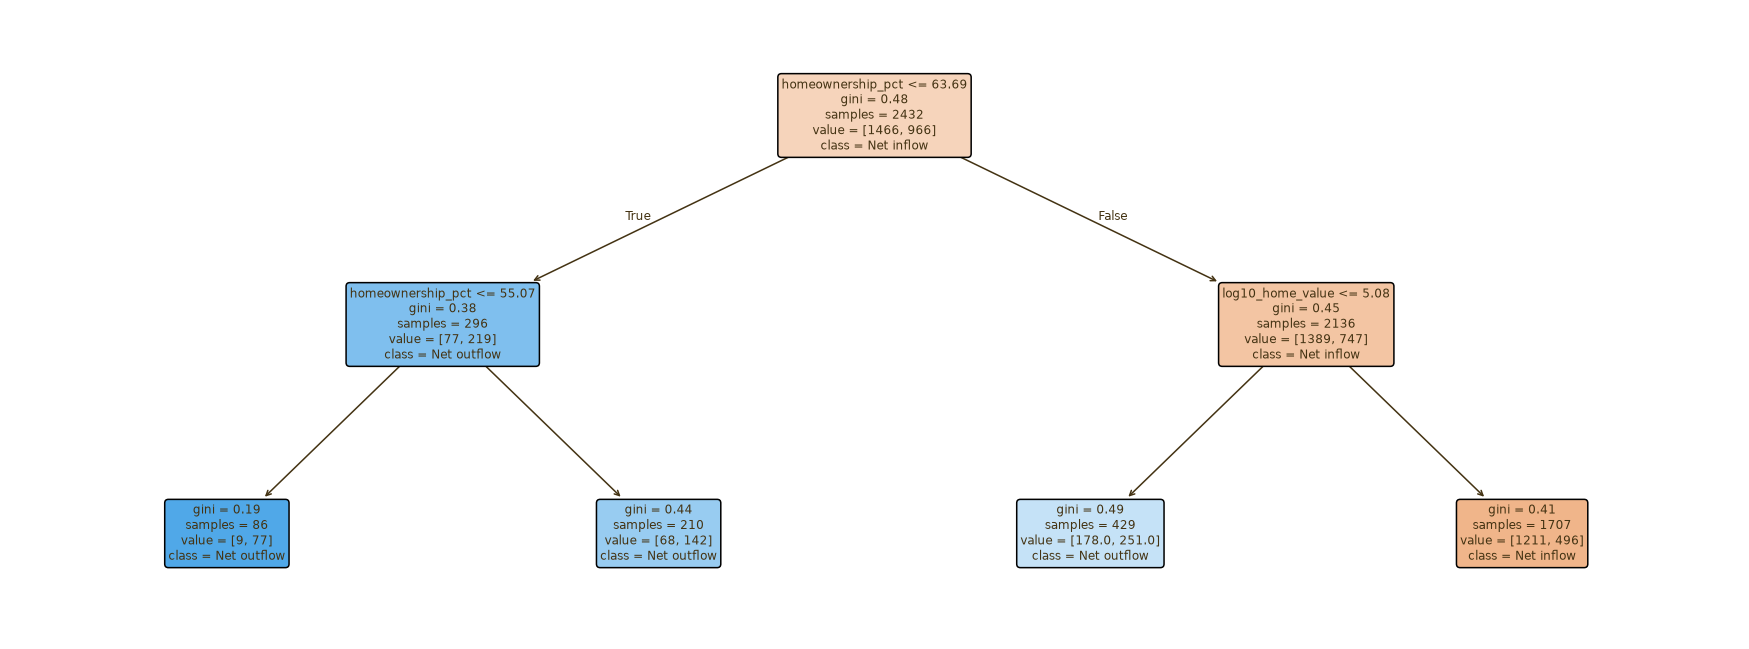

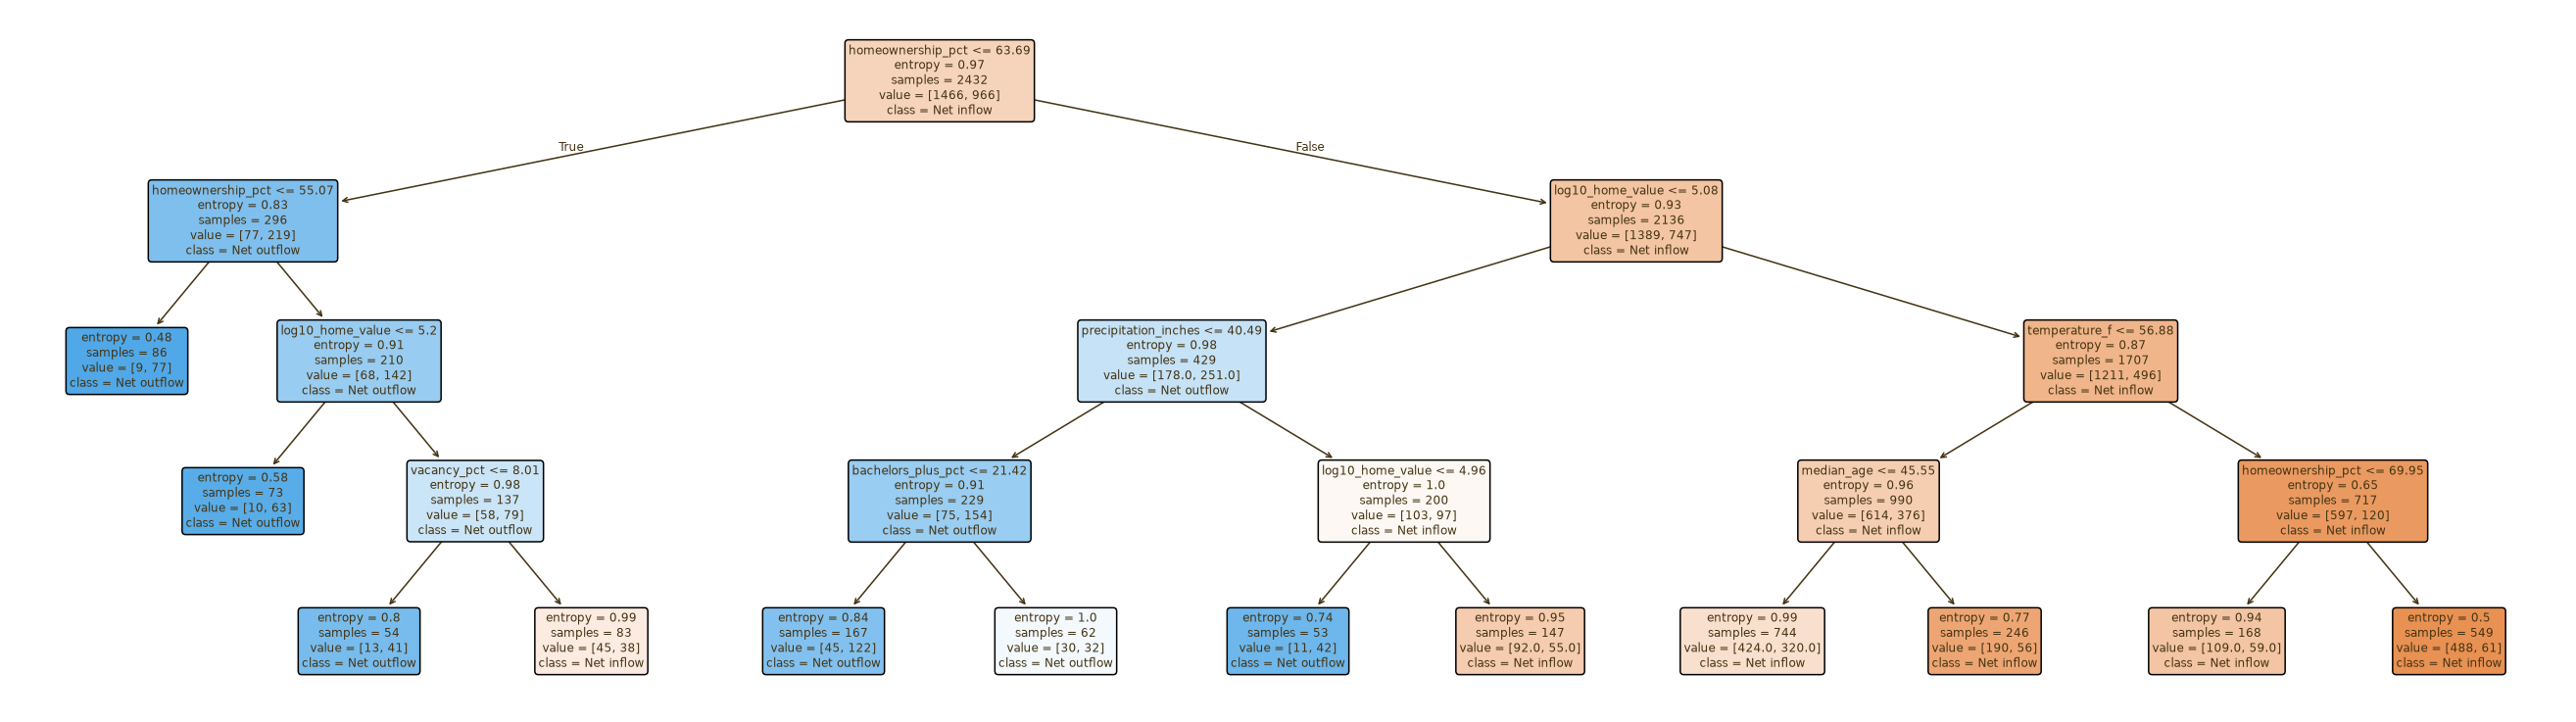

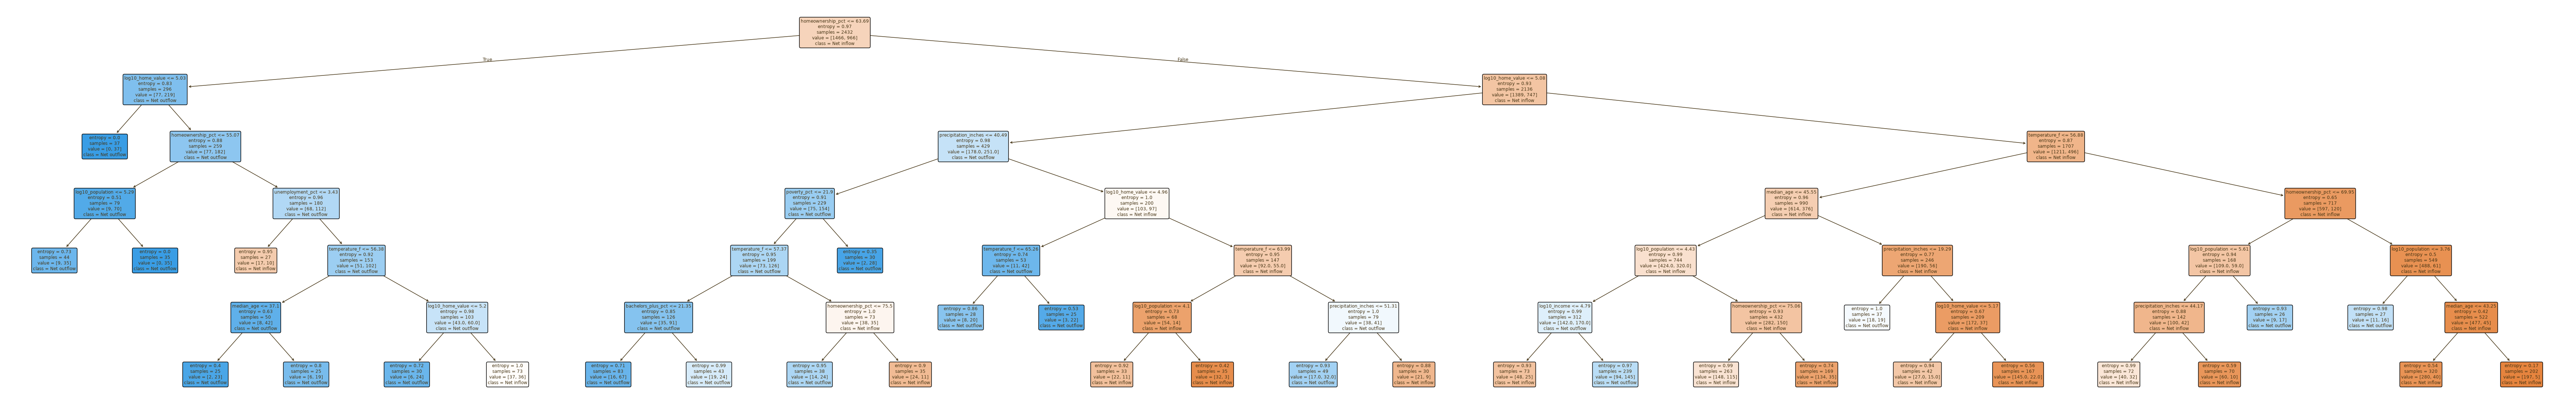

In [4]:
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.base import clone

tasks = {}
selected_models = {}
for outcome in ['outflow', 'net']:
    x_train, x_test, y_train, y_test = task_rows(counties, X, outcome)
    search = GridSearchCV(DecisionTreeClassifier(random_state=SEED, class_weight=None),
        {'max_depth':[2,4,6], 'min_samples_leaf':[10,25,50], 'criterion':['gini','entropy']},
        cv=cv, scoring='f1_macro', return_train_score=True, refit=False, n_jobs=1)
    search.fit(x_train, y_train)
    tuning = pd.DataFrame(search.cv_results_)
    for param in ['max_depth','min_samples_leaf','criterion']:
        tuning[param] = tuning['param_'+param]
    tuning['criterion_order'] = tuning.criterion.map({'gini':0,'entropy':1})
    tuning = tuning.sort_values(['mean_test_score','max_depth','min_samples_leaf','criterion_order'],
                                ascending=[False,True,False,True]).reset_index(drop=True)
    columns = ['max_depth','min_samples_leaf','criterion','mean_train_score','mean_test_score','std_test_score']
    tuning[columns].to_csv(OUT/f'{outcome}-tuning.csv',index=False)
    display(Markdown('### '+outcome.title()+' candidate comparison'))
    display(tuning[columns])
    comparison_plot(tuning, BUNDLE, outcome+'-comparison')
    selected = dict(tuning.iloc[0]['params'])
    selected_models[outcome] = DecisionTreeClassifier(random_state=SEED, **selected).fit(x_train,y_train)
    trees = []
    for depth in [2,4,6]:
        row = tuning.loc[tuning.max_depth.eq(depth)].iloc[0]
        estimator = DecisionTreeClassifier(random_state=SEED, **row['params']).fit(x_train,y_train)
        fig, ax = plt.subplots(figsize=(max(16, estimator.get_n_leaves()*2), max(6, depth*1.7)))
        plot_tree(estimator, feature_names=FEATURES, class_names=estimator.classes_.tolist(),
                  filled=True, rounded=True, precision=2, fontsize=8, ax=ax)
        figure(fig, BUNDLE, f'{outcome}-tree-{depth}', svg=True)
        rules = export_text(estimator,feature_names=FEATURES,decimals=3)
        (OUT/f'{outcome}-tree-{depth}.txt').write_text(rules,encoding='utf-8')
        trees.append({'depth':depth, 'params':row['params'], 'cv_macro_f1':float(row.mean_test_score),
                      'train_macro_f1':float(row.mean_train_score), 'node_count':int(estimator.tree_.node_count),
                      'leaf_count':int(estimator.get_n_leaves()), 'root':tree_structure(estimator)})
    tasks[outcome] = {'outcome':outcome, 'selected':selected, 'train_count':len(x_train),
                      'test_count':len(x_test), 'tuning':records(tuning[columns]), 'trees':trees,
                      'samples':samples_by_task[outcome],
                      'selected_cv_macro_f1':float(tuning.iloc[0].mean_test_score),
                      'selected_train_macro_f1':float(tuning.iloc[0].mean_train_score)}

<a id="results"></a>

## Results

The test counties now evaluate the selected models. Report accuracy alongside balanced accuracy and macro-F1 so an uneven net-direction distribution cannot conceal weak minority-class performance. Confusion matrices retain the same class order in figures and downloads. Tree paths refer to transformed features: for example, log10 home value thresholds can be converted back with 10 raised to that threshold.

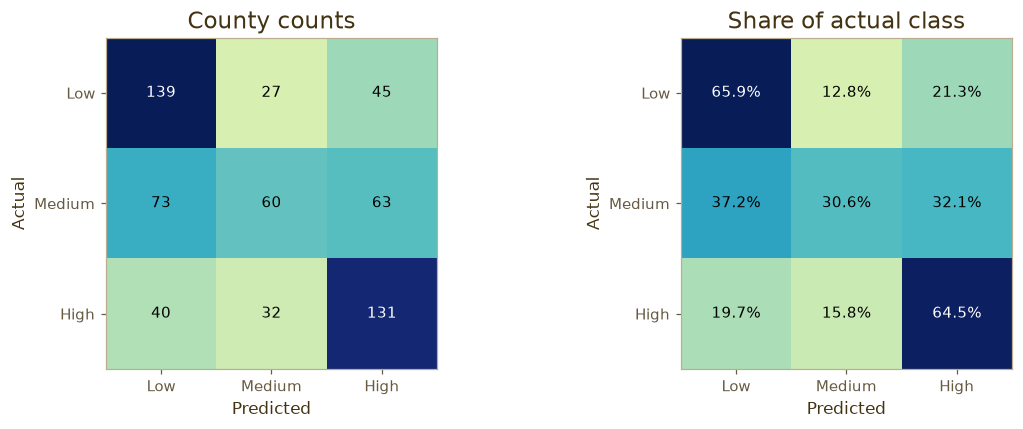

### Outflow held-out results

,accuracy,balanced_accuracy,macro_f1
model,0.540984,0.536737,0.524715
baseline,0.345902,0.333333,0.171336


,precision,recall,f1-score,support
Low,0.551587,0.658768,0.600432,211.000000
Medium,0.504202,0.306122,0.380952,196.000000
High,0.548117,0.645320,0.592760,203.000000
accuracy,0.540984,0.540984,0.540984,0.540984
macro avg,0.534635,0.536737,0.524715,610.000000
weighted avg,0.535207,0.540984,0.527358,610.000000


{'county': 'Autauga County, Alabama',
 'county_fips': '01001',
 'actual': 'High',
 'predicted': 'High',
 'steps': ['log10_rent: 3.079 > 2.945',
  'temperature_f: 66.292 > 55.604',
  'homeownership_pct: 74.910 > 54.323',
  'unemployment_pct: 2.542 <= 4.729',
  'log10_home_value: 5.296 <= 5.354',
  'log10_population: 4.773 > 3.948']}

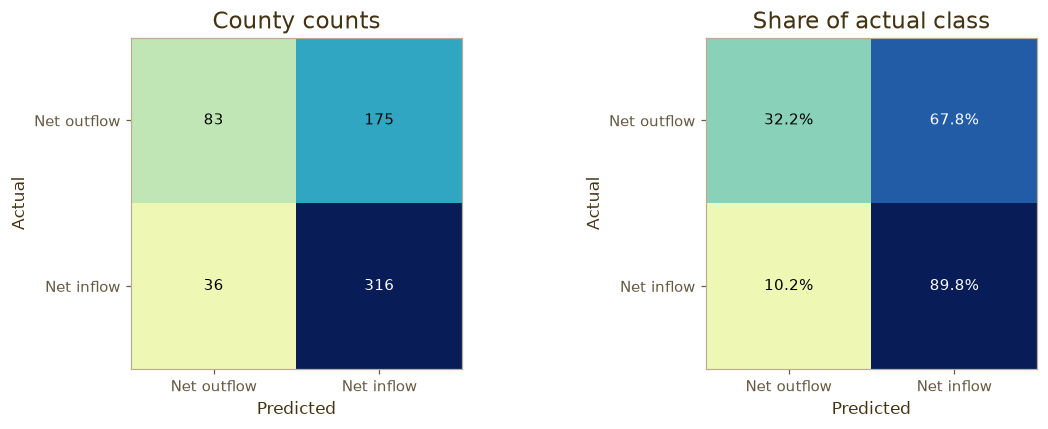

### Net held-out results

,accuracy,balanced_accuracy,macro_f1
model,0.654098,0.609716,0.595011
baseline,0.577049,0.500000,0.365904


,precision,recall,f1-score,support
Net outflow,0.697479,0.321705,0.440318,258.000000
Net inflow,0.643585,0.897727,0.749703,352.000000
accuracy,0.654098,0.654098,0.654098,0.654098
macro avg,0.670532,0.609716,0.595011,610.000000
weighted avg,0.666379,0.654098,0.618849,610.000000


{'county': 'Autauga County, Alabama',
 'county_fips': '01001',
 'actual': 'Net inflow',
 'predicted': 'Net inflow',
 'steps': ['homeownership_pct: 74.910 > 63.691',
  'log10_home_value: 5.296 > 5.079',
  'temperature_f: 66.292 > 56.875',
  'homeownership_pct: 74.910 > 69.946']}

In [5]:
for outcome in ['outflow','net']:
    x_train, x_test, y_train, y_test = task_rows(counties, X, outcome)
    classes = NET_CLASSES if outcome=='net' else RATE_CLASSES
    baseline = DummyClassifier(strategy='most_frequent').fit(x_train,y_train)
    result = tasks[outcome]
    result.update(evaluate(selected_models[outcome],baseline,x_test,y_test,classes,counties,BUNDLE,outcome))
    display(Markdown('### '+outcome.title()+' held-out results'))
    display(pd.DataFrame({k:{m:result[k][m] for m in ['accuracy','balanced_accuracy','macro_f1']} for k in ['model','baseline']}).T)
    display(pd.DataFrame(result['model']['classification_report']).T)
    # A representative test county's path, identified deterministically by FIPS order.
    estimator = selected_models[outcome]
    row = x_test.sort_index().iloc[[0]]
    path = estimator.decision_path(row).indices
    steps = []
    for node in path:
        if estimator.tree_.children_left[node] != -1:
            feature = FEATURES[estimator.tree_.feature[node]]
            value = float(row.iloc[0][feature])
            threshold = float(estimator.tree_.threshold[node])
            steps.append(f"{feature}: {value:.3f} {'<=' if value <= threshold else '>'} {threshold:.3f}")
    result['example_path'] = {'county':counties.loc[row.index[0],'county_name'],
                             'county_fips':counties.loc[row.index[0],'county_fips'],
                             'actual':str(y_test.loc[row.index[0]]), 'predicted':str(estimator.predict(row)[0]), 'steps':steps}
    display(result['example_path'])

<a id="conclusions"></a>

## Conclusions

These findings answer the outflow and net-direction portions of question 9. Tree rules describe predictive associations and conditional partitions. More complex trees may improve training fit while generalizing less well; the validation-selected depth and performance gap make this tradeoff visible.

The combined answer requires the saved Naive Bayes export. Run the Naive Bayes notebook before this concluding synthesis; each notebook otherwise starts directly from the cleaned Parquet dataset. The website reads both exports independently so its combined table always reflects their saved results.

In [6]:
for outcome, result in tasks.items():
    m, b = result['model'], result['baseline']
    weakest = min(m['classes'],key=lambda c:m['classification_report'][c]['recall'])
    result['conclusions'] = [
        f"For {outcome}, the selected depth-{result['selected']['max_depth']} tree classifies {m['accuracy']:.1%} of {result['test_count']:,} held-out counties correctly, compared with {b['accuracy']:.1%} for the majority baseline.",
        f"Macro-F1 is {m['macro_f1']:.3f} versus baseline {b['macro_f1']:.3f}, with balanced accuracy {m['balanced_accuracy']:.1%}. The lowest-recall class is {weakest.lower()} ({m['classification_report'][weakest]['recall']:.1%}).",
        f"Mean training-fold macro-F1 is {result['selected_train_macro_f1']:.3f}, compared with validation {result['selected_cv_macro_f1']:.3f}. The selected model balances fit against validation performance under the fixed candidate grid."
    ]
    for text in result['conclusions']: display(Markdown(text))
write_json(OUT/'decision-trees.json',{'context':context,'tasks':tasks,'worked_example':worked_example})
display(Markdown('Compare these target-specific results with the independent inflow analysis in the website Findings chapter. Export validates matching cohorts, splits and target definitions before combining results.'))

finish_analysis(ROOT, 'classification/decision-trees', BUNDLE)


For outflow, the selected depth-6 tree classifies 54.1% of 610 held-out counties correctly, compared with 34.6% for the majority baseline.

Macro-F1 is 0.525 versus baseline 0.171, with balanced accuracy 53.7%. The lowest-recall class is medium (30.6%).

Mean training-fold macro-F1 is 0.609, compared with validation 0.517. The selected model balances fit against validation performance under the fixed candidate grid.

For net, the selected depth-4 tree classifies 65.4% of 610 held-out counties correctly, compared with 57.7% for the majority baseline.

Macro-F1 is 0.595 versus baseline 0.366, with balanced accuracy 61.0%. The lowest-recall class is net outflow (32.2%).

Mean training-fold macro-F1 is 0.691, compared with validation 0.672. The selected model balances fit against validation performance under the fixed candidate grid.

Compare these target-specific results with the independent inflow analysis in the website Findings chapter. Export validates matching cohorts, splits and target definitions before combining results.

<a id="reading-connections"></a>

## Reading connections

The measured conclusions above answer the outflow and net-direction portions of question 9. [Naive Bayes](naive_bayes.ipynb) addresses inflows independently; website export combines results after validating their provenance.
